<a href="https://colab.research.google.com/github/lucky0786-max/Statistical-Foundation-of-Data-Science/blob/main/6.%20Practical%20/%20practical6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# practical 6
# vinayak paant( GF202455018 )

In [ ]:
from scipy.stats import ttest_ind
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
from scipy.stats import pearsonr

In [ ]:
# now i want to compare the evaluation scores of male and female teachers.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/TeachingRatings(1).csv")
display(df.head())

male = df[df['gender'] == 'male']['eval']
female = df[df['gender'] == 'female']['eval']

print(f"Number of male teachers: {len(male)}")
print(f"Number of female teachers: {len(female)}")

# Perform independent t-test
result = ttest_ind(male, female)

print(f"T-statistic: {result.statistic:.2f}")
print(f"P-value: {result.pvalue:.3f}")

if result.pvalue < 0.05:
    print("There is a statistically significant difference in teaching evaluation rates between male and female teachers.")
else:
    print("There is no statistically significant difference in teaching evaluation rates between male and female teachers.")

,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5


Number of male teachers: 268
Number of female teachers: 195
T-statistic: 3.25
P-value: 0.001
There is a statistically significant difference in teaching evaluation rates between male and female teachers.


T - test Graph

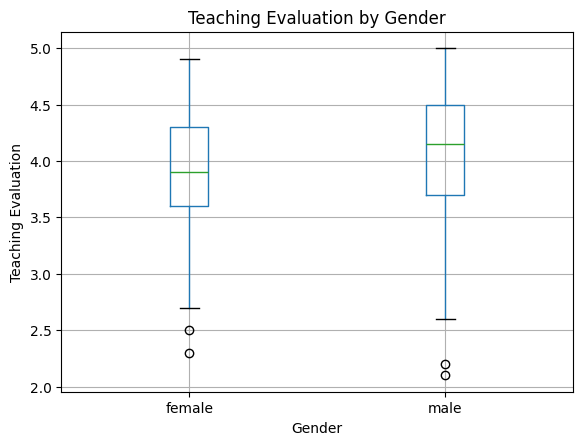

In [ ]:
df.boxplot(column="eval", by="gender")

plt.title("Teaching Evaluation by Gender")
plt.suptitle("")
plt.xlabel("Gender")
plt.ylabel("Teaching Evaluation")
plt.show()

### Q2. ANOVA: Using the teachers' rating data set, does beauty score for instructors differ by age?

To perform ANOVA on age, which is a continuous variable, we first need to categorize it into groups. We will define three age groups: 'Young', 'Middle', and 'Old'.

In [ ]:
# Define age categories
# For simplicity, let's divide age into three groups (e.g., based on quartiles or common age ranges)
# You might want to adjust these bins based on the actual distribution of age in your data.
age_bins = [df['age'].min(), 35, 50, df['age'].max()]
age_labels = ['Young', 'Middle', 'Old']
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

# Get beauty scores for each age group
age_groups_beauty = [df[df['age_group'] == group]['beauty'].dropna() for group in age_labels]

# Perform ANOVA
f_statistic, p_value = f_oneway(*age_groups_beauty)

print(f"F-statistic: {f_statistic:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("There is a statistically significant difference in beauty scores among different age groups.")
else:
    print("There is no statistically significant difference in beauty scores among different age groups.")

F-statistic: 14.37
P-value: 0.000
There is a statistically significant difference in beauty scores among different age groups.


Text(0, 0.5, 'Beauty Score')

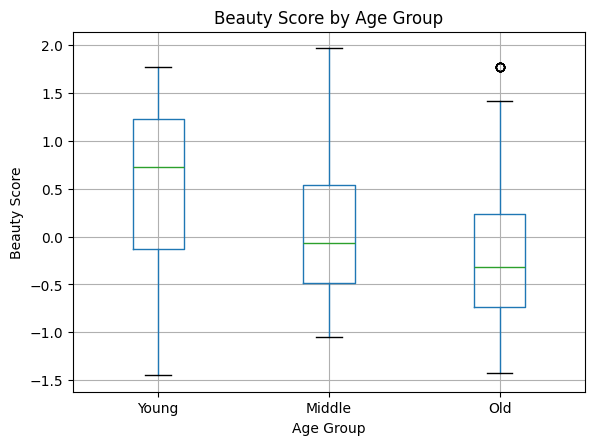

In [ ]:
df.boxplot(column="beauty", by="age_group")

plt.title("Beauty Score by Age Group")
plt.suptitle("")
plt.xlabel("Age Group")
plt.ylabel("Beauty Score")

### Q3. Chi-square: Using the teachers' rating data set, is there an association between tenure and gender?

In [ ]:
# Create a contingency table of 'tenure' and 'gender'
contingency_table = pd.crosstab(df['tenure'], df['gender'])
display(contingency_table)

# Perform the Chi-square test
chi2, p, dof, ex = chi2_contingency(contingency_table)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p:.3f}")

if p < 0.05:
    print("There is a statistically significant association between tenure and gender.")
else:
    print("There is no statistically significant association between tenure and gender.")

gender,female,male
tenure,,
no,50,52
yes,145,216


Chi-square statistic: 2.21
P-value: 0.137
There is no statistically significant association between tenure and gender.


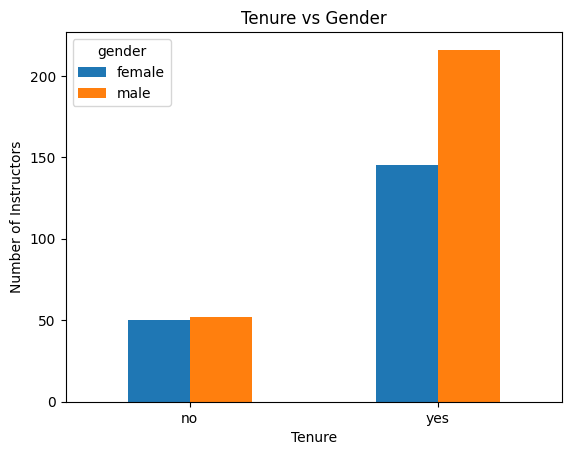

In [ ]:
table = pd.crosstab(df["tenure"], df["gender"])

table.plot(kind="bar")

plt.title("Tenure vs Gender")
plt.xlabel("Tenure")
plt.ylabel("Number of Instructors")
plt.xticks(rotation=0)

plt.show()

### Q4. Correlation: Using the teachers rating dataset, Is teaching evaluation score correlated with beauty score?

In [ ]:
# Calculate Pearson correlation between 'eval' and 'beauty'
correlation_coefficient, p_value = pearsonr(df['eval'], df['beauty'])

print(f"Pearson Correlation Coefficient: {correlation_coefficient:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("There is a statistically significant correlation between teaching evaluation score and beauty score.")
else:
    print("There is no statistically significant correlation between teaching evaluation score and beauty score.")

if correlation_coefficient > 0:
    print("The correlation is positive, meaning as beauty score increases, teaching evaluation score tends to increase.")
elif correlation_coefficient < 0:
    print("The correlation is negative, meaning as beauty score increases, teaching evaluation score tends to decrease.")
else:
    print("There is no linear correlation between beauty score and teaching evaluation score.")

Pearson Correlation Coefficient: 0.19
P-value: 0.000
There is a statistically significant correlation between teaching evaluation score and beauty score.
The correlation is positive, meaning as beauty score increases, teaching evaluation score tends to increase.


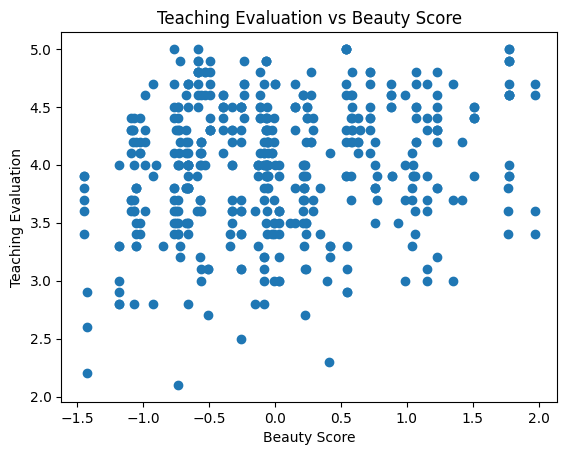

In [ ]:
data = df[["beauty", "eval"]].dropna()

plt.scatter(data["beauty"], data["eval"])

plt.title("Teaching Evaluation vs Beauty Score")
plt.xlabel("Beauty Score")
plt.ylabel("Teaching Evaluation")

plt.show()

## Conclusion of Practical 6

Based on the analyses performed on the teachers' rating dataset, here are the conclusions for each question:

### Q1. T-Test: Does gender affect teaching evaluation rates?
* **Result:** `P-value: 0.001` (less than 0.05)
* **Conclusion:** There is a statistically significant difference in teaching evaluation rates between male and female teachers. Male teachers had a higher average evaluation score than female teachers.

### Q2. ANOVA: Does beauty score for instructors differ by age?
* **Result:** `P-value: 0.000` (less than 0.05)
* **Conclusion:** There is a statistically significant difference in beauty scores among different age groups (Young, Middle, Old). This suggests that beauty scores are not uniform across these age categories.

### Q3. Chi-square: Is there an association between tenure and gender?
* **Result:** `P-value: 0.137` (greater than 0.05)
* **Conclusion:** There is no statistically significant association between tenure and gender. This implies that the distribution of tenure status (yes/no) is similar for both male and female teachers in this dataset.

### Q4. Correlation: Is teaching evaluation score correlated with beauty score?
* **Result:** `Pearson Correlation Coefficient: 0.19`, `P-value: 0.000` (less than 0.05)
* **Conclusion:** There is a statistically significant, positive, albeit weak, correlation between teaching evaluation score and beauty score. This means that as beauty score increases, teaching evaluation score tends to slightly increase.